In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("/Users/meghaprajapati/Downloads/2212311-20_July_2023_Notes/data/data_1.csv",names=["f1","y"])

In [5]:
df

,f1,y
0,-129.366669,28.000000
1,-130.282541,26.380447
2,-119.366669,12.000000
3,-111.659139,2.767886
4,-118.996509,-6.008839
...,...,...
94,115.182359,95.328786
95,128.409173,107.754816
96,131.633331,-114.000000
97,116.384601,-118.214869


In [7]:
df.describe()

,f1,y
count,99.000000,99.000000
mean,18.624101,-16.715312
std,84.660732,59.396962
min,-130.282541,-118.214869
25%,-63.228311,-64.352658
50%,24.203188,-34.000000
75%,105.460471,28.500000
max,132.633331,107.754816


<Axes: xlabel='f1', ylabel='y'>

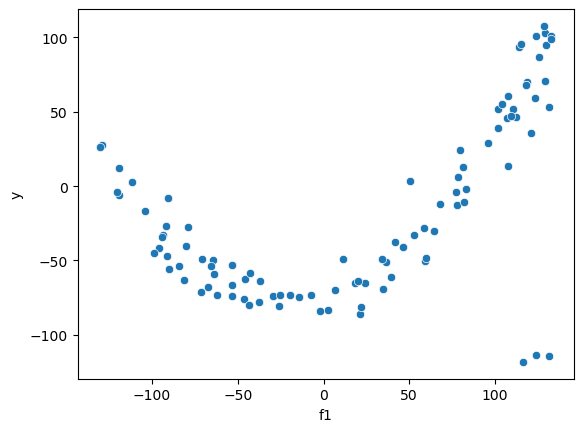

In [9]:
#visualization:
sns.scatterplot(data=df,x="f1",y="y")

In [11]:
# Model Training:
# train test split the data
from sklearn.linear_model import LinearRegression
reg=LinearRegression()
reg.fit(df[["f1"]],df["y"])

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [13]:
# finding the slope and intercept
print(reg.coef_,reg.intercept_)

[0.38221563] -23.833734603860584


In [15]:
# predicting: not splitting the data into training and test but directly applying algorithms.

pred=reg.predict(df[["f1"]])
pred

array([-73.27969793, -73.62975845, -69.45754159, -66.51160316,
       -69.31606065, -69.80406971, -63.72430707, -59.56943119,
       -58.45388337, -59.04606691, -59.90215073, -54.3952281 ,
       -53.92608622, -60.42566907, -56.07999439, -48.57098672,
       -58.64321459, -61.64525532, -54.93334749, -49.65999553,
       -51.02389814, -58.25308302, -51.11119114, -48.32991708,
       -44.15417253, -48.84711469, -47.67125044, -41.25146107,
       -41.49375854, -40.51338225, -44.23130973, -44.28579284,
       -40.21724254, -37.89409878, -35.05813451, -38.31628661,
       -33.65361695, -33.47934697, -26.64939055, -22.85132792,
       -31.3710336 , -29.27807588, -21.29837167, -14.58289791,
       -15.7110852 , -24.50698178, -16.71178406, -19.38566705,
       -15.52698135, -16.0786196 ,  -9.83190265, -10.66318638,
        -3.70274823,  -8.88916719,  -6.0097463 ,  -1.16148054,
       -10.86033455,  -1.02185208,  -1.42315869,   6.01354243,
        -8.00055186,   0.78423554,   2.01678201,   7.52

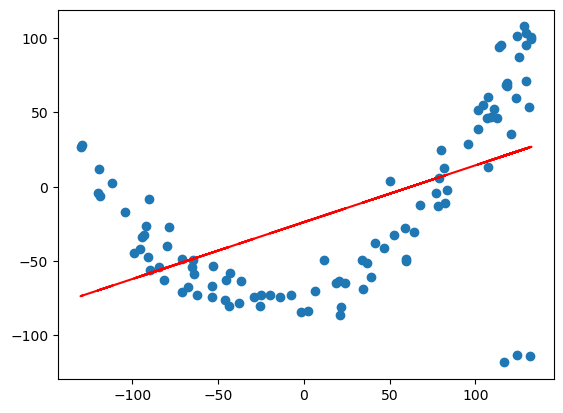

In [17]:
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred,"red")

- In the above scenario of underfitting if we try to use hyperparameter tuning then it will be of no use as only the position of model will change but not the shape of the data.
- So until and unless the shape changes the model will never be able to capture the pattern in the data.
- In order to do so using linear regression we have to perform feature enginering.

# Perfroming Feature Engineering to learn polynomial features:


In [21]:
from sklearn.preprocessing import PolynomialFeatures
poly_features=PolynomialFeatures(degree=2)
x_poly=poly_features.fit_transform(df[["f1"]])  # transform for test data.
x_poly

array([[ 1.00000000e+00, -1.29366669e+02,  1.67357350e+04],
       [ 1.00000000e+00, -1.30282541e+02,  1.69735404e+04],
       [ 1.00000000e+00, -1.19366669e+02,  1.42484016e+04],
       [ 1.00000000e+00, -1.11659139e+02,  1.24677633e+04],
       [ 1.00000000e+00, -1.18996509e+02,  1.41601691e+04],
       [ 1.00000000e+00, -1.20273299e+02,  1.44656664e+04],
       [ 1.00000000e+00, -1.04366669e+02,  1.08924015e+04],
       [ 1.00000000e+00, -9.34961665e+01,  8.74153316e+03],
       [ 1.00000000e+00, -9.05775318e+01,  8.20428927e+03],
       [ 1.00000000e+00, -9.21268759e+01,  8.48736126e+03],
       [ 1.00000000e+00, -9.43666687e+01,  8.90506816e+03],
       [ 1.00000000e+00, -7.99587739e+01,  6.39340553e+03],
       [ 1.00000000e+00, -7.87313467e+01,  6.19862495e+03],
       [ 1.00000000e+00, -9.57363624e+01,  9.16545108e+03],
       [ 1.00000000e+00, -8.43666687e+01,  7.11773479e+03],
       [ 1.00000000e+00, -6.47206705e+01,  4.18876519e+03],
       [ 1.00000000e+00, -9.10728836e+01

In [23]:
# transforming the above array into df
transformed_df=pd.DataFrame(x_poly,columns=["f1_0","f1_1","f1_2"])
transformed_df["y"]=df["y"]
transformed_df

,f1_0,f1_1,f1_2,y
0,1.0,-129.366669,16735.734971,28.000000
1,1.0,-130.282541,16973.540359,26.380447
2,1.0,-119.366669,14248.401597,12.000000
3,1.0,-111.659139,12467.763278,2.767886
4,1.0,-118.996509,14160.169083,-6.008839
...,...,...,...,...
94,1.0,115.182359,13266.975917,95.328786
95,1.0,128.409173,16488.915659,107.754816
96,1.0,131.633331,17327.333909,-114.000000
97,1.0,116.384601,13545.375303,-118.214869


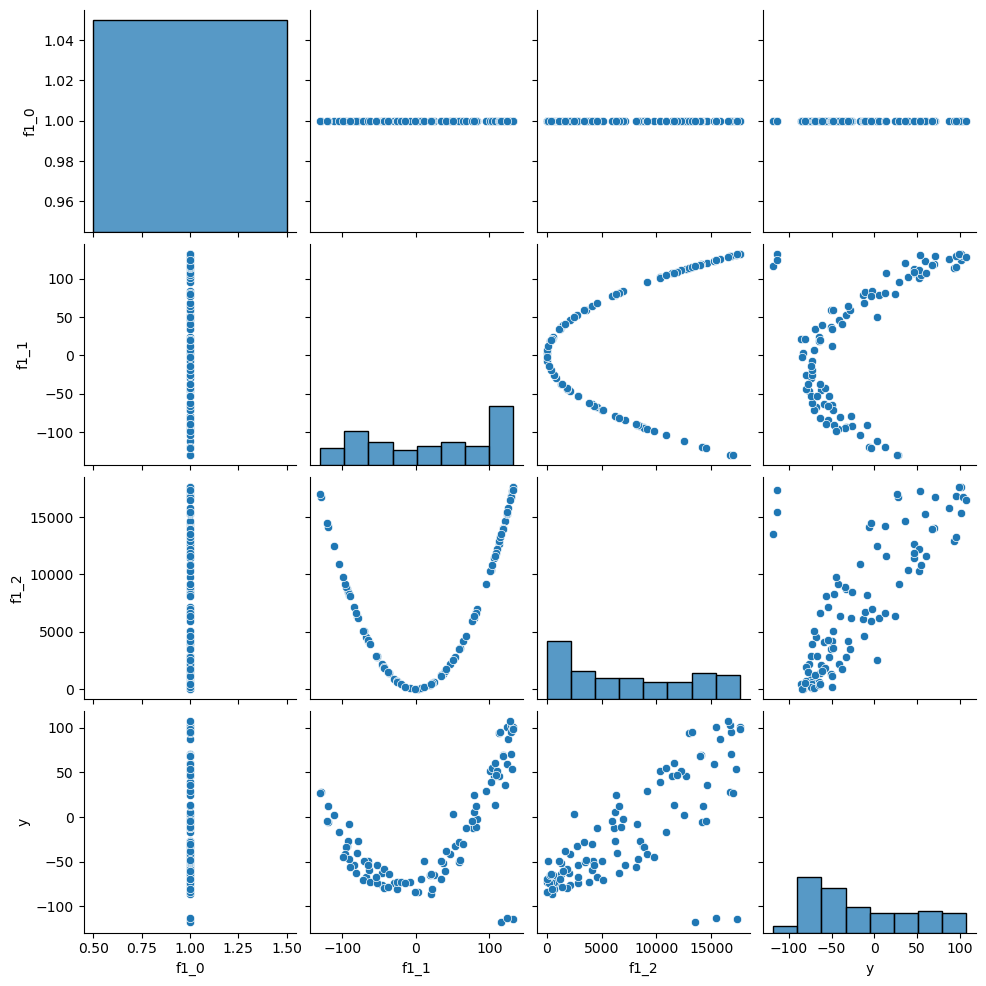

In [25]:
# plotting the graph for the current data

sns.pairplot(transformed_df)

In [26]:
reg_poly=LinearRegression()
reg_poly.fit(transformed_df[["f1_0","f1_1","f1_2"]],transformed_df["y"])

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
# pred 
pred_poly=reg_poly.predict(transformed_df[["f1_0","f1_1","f1_2"]])

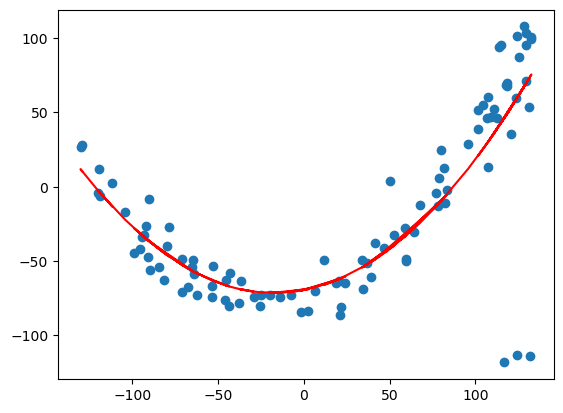

In [28]:
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred_poly,"red")

# Other Regression models: (Lasso, Ridge and ElasticNet)

In [37]:
from sklearn.linear_model import Lasso,Ridge,ElasticNet  # Lasso- L1- sparsity in data to reduce the dimensionality


In [41]:
reg_lasso=Lasso(alpha=1.0)
reg_lasso.fit(transformed_df[["f1_0","f1_1","f1_2"]],transformed_df["y"])

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [43]:
pred_lasso=reg_lasso.predict(transformed_df[["f1_0","f1_1","f1_2"]])

In [47]:
pred_lasso,transformed_df["y"]

(array([ 10.48275807,  11.82950197,  -3.50824831, -13.39977322,
         -4.00104898,  -2.29366933, -22.04363916, -33.63806168,
        -36.48800565, -34.98899254, -32.76648726, -45.91725115,
        -46.91214189, -31.37505052, -42.18207203, -56.87301254,
        -36.01215808, -28.03844932, -44.75183112, -55.05524096,
        -52.62893108, -36.98917365, -52.46797359, -57.26105939,
        -63.15750419, -56.42214299, -58.29479168, -66.33703399,
        -66.10047098, -67.02526954, -63.06272649, -62.99546278,
        -67.2877073 , -69.07421326, -70.60045658, -68.78545751,
        -71.08985567, -71.13826929, -70.89529013, -68.95411855,
        -71.50865911, -71.48293042, -67.78860793, -60.2642037 ,
        -61.81032179, -69.95901936, -63.0864067 , -66.05651655,
        -61.56579428, -62.28941127, -52.50349391, -54.00717597,
        -39.50789731, -50.72338241, -44.79392927, -33.13382705,
        -54.35471926, -32.76685922, -33.81686414, -12.01808087,
        -48.97265097, -27.86291791, -24.

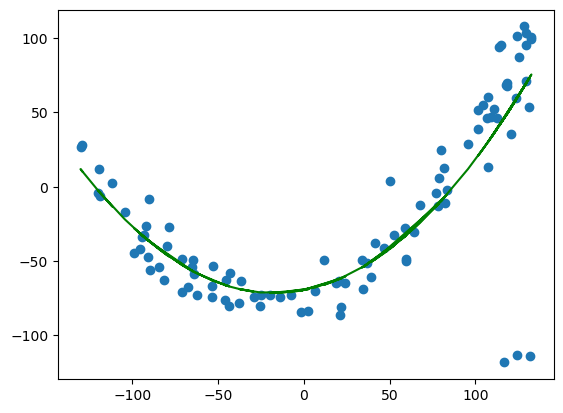

In [49]:
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred_lasso,"green")

In [51]:
# ridge implementation
reg_ridge=Ridge(alpha=1.0)
reg_ridge.fit(transformed_df[["f1_0","f1_1","f1_2"]],transformed_df["y"])

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [53]:
pred_ridge=reg_ridge.predict(transformed_df[["f1_0","f1_1","f1_2"]])


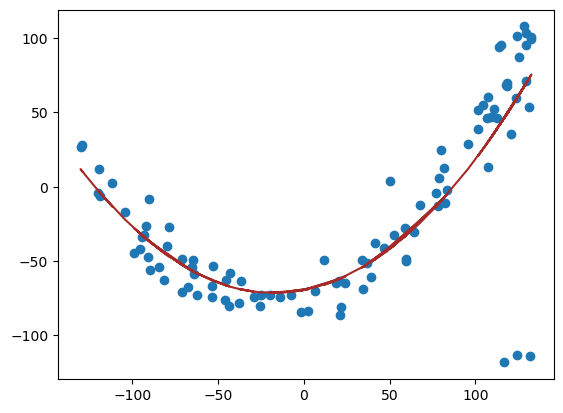

In [61]:
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred_ridge,"brown")

In [63]:
# ElasticNet implementation:
reg_elastic=ElasticNet(alpha=1.0)
reg_elastic.fit(transformed_df[["f1_0","f1_1","f1_2"]],transformed_df["y"])

,alpha,1.0
,l1_ratio,0.5
,fit_intercept,True
,precompute,False
,max_iter,1000
,copy_X,True
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [65]:
pred_elastic=reg_elastic.predict(transformed_df[["f1_0","f1_1","f1_2"]])

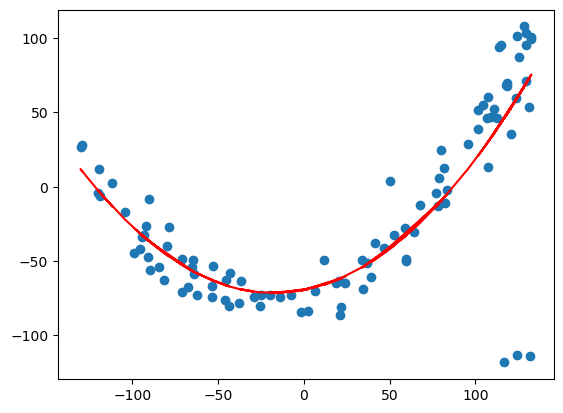

In [69]:
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred_elastic,"red")